In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import DensityMatrix, entropy
import bosonic_qiskit as c2qa

# ------------------------------- USER PARAMETERS ------------------------------------
N_SITES   = 7    
                       
CUTOFF    = 2          # Fock truncation per qumode (photon numbers 0..CUTOFF-1)
USE_MPS   = True       # matrix_product_state backend 

wc        = 1.0        # cavity frequency
wa        = 1.0        # atom frequency
DETUNING  = wc - wa    
g         = 0.35        # Jaynes-Cummings coupling
J         = 0.50       # inter-site photon hopping

DT        = 0.05       # Trotter step size
N_STEPS   = 3000  # -> T_max = N_STEPS * DT

INIT_SITE = N_SITES-3  # site that starts with 1 photon; rest vacuum, atoms in |g>
ENT_SITE  = INIT_SITE       # single-site reference for a quick entropy check
ADD_SITE = INIT_SITE-2
#ADD_SITE2=ADD_SITE-2
ent_site = list(range(N_SITES // 2))  # sites whose entropy vs. the rest is wanted
# --------------------------------------------------------------------------------------

m = int(np.ceil(np.log2(CUTOFF)))          # qubits per qumode
total_qubits = N_SITES * (m + 1)
print(f"[info] N_SITES={N_SITES}, CUTOFF={CUTOFF} -> {m} qubit(s)/qumode, "
      f"{total_qubits} total qubits")

qmr = c2qa.QumodeRegister(num_qumodes=N_SITES, num_qubits_per_qumode=m)
qr  = qiskit.QuantumRegister(N_SITES, name="atom")
circuit = c2qa.CVCircuit(qmr, qr)

# ------------------------------- initial state ---------------------------------------

for i in range(N_SITES):
    circuit.cv_initialize(1 if i == INIT_SITE or i == ADD_SITE else 0, qmr[i])
    circuit.x(qr[i])              

# ------------------------------- qubit-index bookkeeping ------------------------------
def qumode_qubits(site):
    return list(range(site * m, site * m + m))

def atom_qubit(site):
    return N_SITES * m + site

def site_block(site):
    return qumode_qubits(site) + [atom_qubit(site)]

def site_block_list(sites):
    qubits = []
    for site in sites:
        qubits.extend(site_block(site))
    return qubits

# ------------------------------- local operators (dense, tiny) ------------------------
def number_op_mode():
    dim = 2 ** m
    return np.diag([min(k, CUTOFF - 1) for k in range(dim)]).astype(complex)

# 2) occupancy operator — flip which computational state counts as "excited"
def number_op_atom():
    return np.diag([1.0, 0.0]).astype(complex)   # <-- was [0.0, 1.0]

N_MODE_OP = number_op_mode()
N_ATOM_OP = number_op_atom()
# total (polariton) number op on one site's block == kron(n_mode, I2) + kron(I_dimmode, n_atom)
I_MODE = np.eye(2 ** m)
I_ATOM = np.eye(2)
N_SITE_OP = np.kron(N_ATOM_OP, I_MODE) + np.kron(I_ATOM, N_MODE_OP)

# N_SITE_OP = np.kron(N_MODE_OP, np.eye(2)) + np.kron(I_MODE, N_ATOM_OP)

# ------------------------------- build circuit + save instructions --------------------
def append_trotter_step(circ):
    # on-site Jaynes-Cummings coupling g(a^dag sigma- + a sigma+)
    for i in range(N_SITES):
        circ.cv_jc(g * DT, 0.0, qmr[i], qr[i])
        circ.barrier()

        

    # if abs(DETUNING) > 1e-12:
    #     for i in range(N_SITES):
    #         circ.cv_r(wc * DT, qmr[i])
    #         circ.rz(wa * DT, qr[i])
    #         circ.barrier()

    # nearest-neighbour photon hopping (beamsplitter realizes a_i^dag a_j + h.c.)
    for i in range(N_SITES - 1):
        circ.cv_bs(-J * DT, qmr[i], qmr[i + 1])
        circ.barrier()
        


[info] N_SITES=7, CUTOFF=2 -> 1 qubit(s)/qumode, 14 total qubits


In [13]:
#print(f"{ent_site}")
labels_occ = []   # (t_index, site) -> label
#labels_ent = []   # t_index -> label

for site in range(N_SITES):
    lbl = f"occ_s{site}_t0"
    circuit.save_density_matrix(qubits=site_block(site), label=lbl)
    labels_occ.append((0, site, lbl))

# ent_qubits = site_block_list(ent_site)
# lbl = "ent_t0"
# circuit.save_density_matrix(qubits=ent_qubits, label=lbl)
# labels_ent.append((0, lbl))

for t in range(1, N_STEPS + 1):
    append_trotter_step(circuit)
    for site in range(N_SITES):
        lbl = f"occ_s{site}_t{t}"
        circuit.save_density_matrix(qubits=site_block(site), label=lbl)
        labels_occ.append((t, site, lbl))
    # lbl = f"ent_t{t}"
    # circuit.save_density_matrix(qubits=ent_qubits, label=lbl)
    # labels_ent.append((t, lbl))

In [14]:
# ------------------------------- run ---------------------------------------------------
backend = AerSimulator(method="matrix_product_state" if USE_MPS else "statevector")
tcirc = transpile(circuit, backend)
result = backend.run(tcirc).result()
#print(result.results[0].metadata.get("method"))
data = result.data(0)
np.savez("jch_multi_exc_data.npz", **data)
# ------------------------------- post-process -----------------------------------------
occupancy = np.zeros((N_SITES, N_STEPS + 1))
for (t, site, lbl) in labels_occ:
    rho = np.asarray(data[lbl])
    occupancy[site, t] = np.real(np.trace(rho @ N_SITE_OP))

# ent_S = np.zeros(N_STEPS + 1)
# for (t, lbl) in labels_ent:
#     rho = np.asarray(data[lbl])
#     dm = DensityMatrix(rho)
#     ent_S[t] = entropy(dm, base=2)  # von Neumann entropy of ENT_SITE vs rest of chain

times = np.arange(N_STEPS + 1) * DT

In [15]:
print("total occupancy min/max:", occupancy.sum(axis=0).min(), occupancy.sum(axis=0).max())


total occupancy min/max: 1.999999999970096 2.0000000000211076


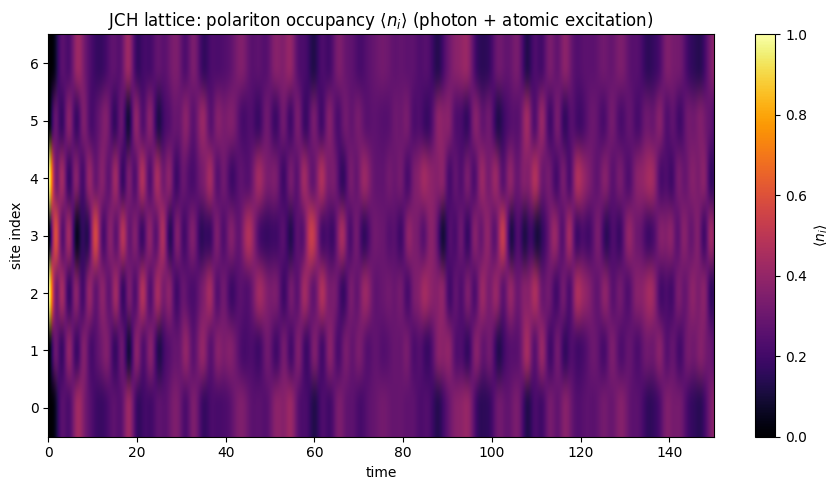

In [17]:


fig1, ax1 = plt.subplots(figsize=(9, 5))
im = ax1.imshow(occupancy, aspect="auto", origin="lower",
                 extent=[times[0], times[-1], -0.5, N_SITES - 0.5], cmap="inferno")
ax1.set_xlabel("time")
ax1.set_ylabel("site index")
ax1.set_title("JCH lattice: polariton occupancy $\\langle n_i \\rangle$ (photon + atomic excitation)")
fig1.colorbar(im, ax=ax1, label=r"$\langle n_i \rangle$")
fig1.tight_layout()
fig1.savefig(f"jch_occupancy_2_excited{N_SITES}.pdf", dpi=150)
plt.show()

In [ ]:
# uncomment the codes in backend section to get the entanglement entropy plot
ent_S = np.zeros(N_STEPS + 1)
for (t, lbl) in labels_ent:
    rho = np.asarray(data[lbl])
    dm = DensityMatrix(rho)
    ent_S[t] = entropy(dm, base=2)  




fig2, ax2 = plt.subplots(figsize=(9,5))
ax2.plot(times, ent_S, marker="o", ms=3)
ax2.set_xlabel("time")
ax2.set_ylabel(f"$S_{{vN}}$ (site {ENT_SITE} vs. rest of chain)")
ax2.set_title("Entanglement entropy growth")
fig2.tight_layout()
#fig2.savefig(f"jch_entanglement_entropy{N_SITES}.png", dpi=150)

plt.show()

